# Task III — Model 2: Attention U-Net flood mapping on Satna (Dataset II)
**CS F425 Deep Learning · Team 26**

Dataset II is cut from the Task-II outputs for Satna district (Madhya Pradesh):
before = Sentinel-1A, 18 May 2026; after = Sentinel-1D, 10 Sep 2026; Gamma0 dB after Refined Lee
filtering and terrain correction. Ground truth: the cleaned VH dB flood mask from Task II.

Input: 4 stacked bands in dB (before VV, before VH, after VV, after VH), 64 × 64 patches.
Model: Attention U-Net (U-Net with attention gates on the skip connections).

**How to run**
* **Google Colab** (Runtime → T4 GPU): put the project folder in Google Drive as `MyDrive/DL_Project/`
  with `Dataset-I/Codes/`, `Satna/` and `Task III/Codes/` inside it, then *Run all*.
* **Local computer**: keep this notebook in `<project>/Task III/Codes/`, install
  `torch numpy rasterio matplotlib pandas` and *Run all*.

The last cell is a standalone **test cell** that only needs the saved weights and a test-data folder.

In [1]:
# ---- 1. Setup: install packages and locate the project folder ----
import os, sys, subprocess

if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio'], check=True)   # only package Colab lacks
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/DL_Project'    # holds Dataset-I/, Satna/ and Task III/
else:
    PROJECT_DIR = os.path.abspath('../..')               # this notebook lives in <PROJECT_DIR>/Task III/Codes
print('Project folder:', PROJECT_DIR)

Project folder: /mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project


In [2]:
# ---- 2. Settings ----
DISTRICT = 'Satna'                                                # <- the only name to change for another district
DISTRICT_DIR = f'{PROJECT_DIR}/{DISTRICT}'                        # Task-II outputs (dB rasters + mask)
RASTERS = {
    'before_vh': f'{DISTRICT_DIR}/Before/VH/{DISTRICT}_Before_VH_dB.tif',  # 18 May 2026
    'before_vv': f'{DISTRICT_DIR}/Before/VV/{DISTRICT}_Before_VV_dB.tif',
    'after_vh': f'{DISTRICT_DIR}/After/VH/{DISTRICT}_After_VH_dB.tif',     # 10 Sep 2026
    'after_vv': f'{DISTRICT_DIR}/After/VV/{DISTRICT}_After_VV_dB.tif',
    'mask': f'{DISTRICT_DIR}/Mask/Cleaned_flood_mask.tif',            # cleaned VH dB mask from Task II
}
PATCH_SCRIPT = f'{PROJECT_DIR}/Dataset-I/Codes/make_patches_updated.py'
DATA_DIR = f'{PROJECT_DIR}/Task III/Dataset_II'                   # patches (same layout as Dataset-I)
WEIGHTS_PATH = f'{PROJECT_DIR}/Task III/Codes/Model_2_weights.pth'
OUTPUT_DIR = f'{PROJECT_DIR}/Task III/Outputs/Model_2'            # plots + metrics for the report
os.makedirs(OUTPUT_DIR, exist_ok=True)

MIN_VALID_FRAC = 0.80     # skip a patch if any band has < 80 % valid (non-NaN, non-zero) pixels
MIN_FLOOD_FRAC = 0.05     # skip a patch if < 5 % of its valid pixels are flood
VAL_FRAC = 0.20           # share of spatial blocks used for validation
MODEL_ARGS = dict(in_channels=4, base=32)
EPOCHS = 40
BATCH_SIZE = 64
LR = 1e-3
SEED = 42
MODEL_NAME = f'Model 2 (Attention U-Net, {DISTRICT})'

## 3. Data helpers and model architecture

In [3]:
import os, glob
import numpy as np
import rasterio
from rasterio.transform import from_origin

BANDS = ['before_VV', 'before_VH', 'after_VV', 'after_VH']   # channel order of the model input
PATCH = 64                                                    # patch size in pixels


def read_tif(path):
    """Return (band 1 as array, geo-transform, CRS) of a GeoTIFF."""
    with rasterio.open(path) as src:
        return src.read(1), src.transform, src.crs


def write_tif(path, array, transform, crs):
    """Save a single-band uint8 GeoTIFF (0 = no flood, 255 = flood)."""
    profile = dict(driver='GTiff', height=array.shape[0], width=array.shape[1], count=1,
                   dtype='uint8', crs=crs, transform=transform, compress='lzw')
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(array, 1)


def patch_ids(folder):
    """IDs of all patches in a Dataset-I style folder, e.g. 'K_012_034' = region_row_col."""
    files = glob.glob(f'{folder}/after_VH/*_after_VH.tif')
    return sorted(os.path.basename(f)[:-len('_after_VH.tif')] for f in files)


def read_patch(folder, pid):
    """Return the 4 stacked SAR bands (4, 64, 64) in dB, the 0/1 mask (None if missing),
    and the geo-transform + CRS of the patch."""
    bands = [read_tif(f'{folder}/{band}/{pid}_{band}.tif') for band in BANDS]
    image = np.stack([array for array, _, _ in bands]).astype(np.float32)
    _, transform, crs = bands[0]

    mask_path = f'{folder}/mask/{pid}_mask.tif'
    mask = (read_tif(mask_path)[0] > 0).astype(np.float32) if os.path.exists(mask_path) else None
    return image, mask, transform, crs


def valid_pixels(image):
    """No-data pixels are NaN or exactly 0 dB (outside the satellite swath)."""
    return np.isfinite(image) & (image != 0)


def normalize(image, mean, std):
    """Standardise each band with the training mean/std. No-data pixels become 0 (= the band mean)."""
    mean = np.asarray(mean, np.float32)[:, None, None]
    std = np.asarray(std, np.float32)[:, None, None]
    return np.where(valid_pixels(image), (image - mean) / std, 0).astype(np.float32)

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Sequential):
    """Two (3x3 convolution -> batch norm -> ReLU) layers."""
    def __init__(self, in_ch, out_ch):
        super().__init__(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018): scales every skip-connection pixel by a
    0..1 weight computed from the skip features and the decoder (gating) features."""
    def __init__(self, channels):
        super().__init__()
        self.w_skip = nn.Conv2d(channels, channels // 2, 1)
        self.w_gate = nn.Conv2d(channels, channels // 2, 1)
        self.psi = nn.Sequential(nn.ReLU(inplace=True), nn.Conv2d(channels // 2, 1, 1), nn.Sigmoid())

    def forward(self, skip, gate):
        weights = self.psi(self.w_skip(skip) + self.w_gate(gate))    # (B, 1, H, W)
        return skip * weights


class AttentionUNet(nn.Module):
    """U-Net whose skip connections pass through attention gates, so the decoder can focus
    on flood-relevant regions and ignore background clutter (speckle, vegetation change)."""
    def __init__(self, in_channels=4, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]          # 32, 64, 128, 256, 512
        self.encoders = nn.ModuleList([DoubleConv(in_channels, ch[0])] +
                                      [DoubleConv(ch[i], ch[i + 1]) for i in range(4)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(4)])
        self.gates = nn.ModuleList([AttentionGate(ch[i]) for i in range(4)])
        self.decoders = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in range(4)])
        self.head = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x):
        skips = []
        for i, encoder in enumerate(self.encoders):
            x = encoder(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()                                               # bottleneck (4x4)
        for i in reversed(range(4)):
            up = self.ups[i](x)
            skip = self.gates[i](skips[i], up)                       # attention-weighted skip
            x = self.decoders[i](torch.cat([up, skip], dim=1))
        return self.head(x)

In [5]:
import json, random
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader


def load_dataset(folder, ids=None):
    """Read the patches of `folder` and keep only the usable ones. A patch is skipped when
      * any of the 4 SAR bands has < MIN_VALID_FRAC valid pixels (black / no-data patch), or
      * fewer than MIN_FLOOD_FRAC of its valid pixels are flood."""
    images, masks, kept = [], [], []
    skipped_nodata = skipped_low_flood = 0
    for pid in (patch_ids(folder) if ids is None else ids):
        image, mask, _, _ = read_patch(folder, pid)
        valid = valid_pixels(image)
        if valid.mean(axis=(1, 2)).min() < MIN_VALID_FRAC:
            skipped_nodata += 1
            continue
        if mask[valid.all(axis=0)].mean() < MIN_FLOOD_FRAC:
            skipped_low_flood += 1
            continue
        images.append(image)
        masks.append(mask)
        kept.append(pid)

    counts = dict(kept=len(kept), skipped_nodata=skipped_nodata, skipped_low_flood=skipped_low_flood)
    print(f'{folder}: {counts}')
    return np.stack(images), np.stack(masks), kept, counts


def band_stats(images):
    """Mean and standard deviation of every band over its valid pixels (training set only)."""
    valid = valid_pixels(images)
    mean = [float(images[:, b][valid[:, b]].mean()) for b in range(len(BANDS))]
    std = [float(images[:, b][valid[:, b]].std()) for b in range(len(BANDS))]
    return mean, std


def make_loader(images, masks, mean, std, shuffle):
    x = torch.from_numpy(normalize(images, mean, std))
    y = torch.from_numpy(masks).unsqueeze(1)                          # (N, 1, 64, 64)
    return DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=shuffle)


def augment(x, y):
    """Random flips and 90-degree rotations, applied identically to image and mask.
    Flood water has no preferred orientation, so this adds variety without changing labels."""
    if random.random() < 0.5:
        x, y = x.flip(-1), y.flip(-1)
    if random.random() < 0.5:
        x, y = x.flip(-2), y.flip(-2)
    k = random.randint(0, 3)
    return torch.rot90(x, k, (-2, -1)), torch.rot90(y, k, (-2, -1))


def loss_fn(logits, target):
    """Binary cross-entropy + soft Dice loss (Dice helps with the flood / non-flood imbalance)."""
    prob = torch.sigmoid(logits)
    dice = (2 * (prob * target).sum() + 1) / (prob.sum() + target.sum() + 1)
    return F.binary_cross_entropy_with_logits(logits, target) + (1 - dice)


@torch.no_grad()
def evaluate(model, loader):
    """Average loss, plus IoU and Dice computed over all pixels of the split (threshold 0.5)."""
    model.eval()
    total_loss, tp, fp, fn = 0.0, 0.0, 0.0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(x)
        pred = (logits > 0).float()                                   # logit > 0  <=>  probability > 0.5
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
    return dict(loss=total_loss / len(loader.dataset),
                iou=tp / (tp + fp + fn + 1e-9),
                dice=2 * tp / (2 * tp + fp + fn + 1e-9))


def check_alignment(folder, ids):
    """All 5 files of a patch must have the same size, CRS and geo-transform."""
    for pid in ids:
        grids = []
        for name in BANDS + ['mask']:
            with rasterio.open(f'{folder}/{name}/{pid}_{name}.tif') as src:
                grids.append((src.shape, src.crs, src.transform))
        assert all(grid == grids[0] for grid in grids), f'{pid}: files are not aligned'
    print(f'Alignment OK for {len(ids)} patches (same shape, CRS and transform in all 5 files).')


def show_collage(images, masks, preds, ids, title, path=None):
    """One row per patch: the 4 SAR bands (dB), the ground truth and, if given, the prediction."""
    columns = ['Before VV', 'Before VH', 'After VV', 'After VH', 'Ground truth']
    if preds is not None:
        columns.append('Prediction')
    fig, axes = plt.subplots(len(ids), len(columns), figsize=(2.3 * len(columns), 2.4 * len(ids)), squeeze=False)
    for r, pid in enumerate(ids):
        panels = list(images[r]) + [masks[r]] + ([preds[r]] if preds is not None else [])
        for c, panel in enumerate(panels):
            ax = axes[r, c]
            if c < 4:                                                 # SAR band: 2-98 % contrast stretch
                vmin, vmax = np.nanpercentile(panel, [2, 98])
                ax.imshow(panel, cmap='gray', vmin=vmin, vmax=vmax)
            else:                                                     # mask: white = flood
                ax.imshow(panel, cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(columns[c])
        axes[r, 0].set_ylabel(pid)
    fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()


def plot_losses(history, title, path):
    plt.figure(figsize=(7, 4))
    plt.plot(history['epoch'], history['train_loss'], label='training loss')
    plt.plot(history['epoch'], history['val_loss'], label='validation loss')
    plt.xlabel('epoch')
    plt.ylabel('BCE + Dice loss')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


## 4. Build Dataset II (patches) from the Task-II rasters

In [6]:
# Cut the four dB rasters and the mask into aligned 64x64 patches with the course script
# (stride 54 = 10 px overlap). It only keeps patches with >= 80 % valid pixels in all five
# rasters and >= 5 % flood; --zero_is_nodata also treats 0 dB (single-date swath edge) as no-data.
# Takes a while, so it only runs if Dataset_II does not exist yet.
if not os.path.exists(f'{DATA_DIR}/patch_index.csv'):
    command = [sys.executable, PATCH_SCRIPT,
               '--before_vh', RASTERS['before_vh'], '--before_vv', RASTERS['before_vv'],
               '--after_vh', RASTERS['after_vh'], '--after_vv', RASTERS['after_vv'],
               '--mask', RASTERS['mask'], '--out', DATA_DIR, '--district', DISTRICT,
               '--min_valid', str(MIN_VALID_FRAC), '--min_flood', str(MIN_FLOOD_FRAC),
               '--zero_is_nodata', '--no_preview']
    result = subprocess.run(command, capture_output=True, text=True)
    print('\n'.join(result.stdout.splitlines()[-6:]))       # summary lines of the script
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
else:
    print('Dataset_II already exists:', DATA_DIR)

[progress] Row 399/399 completed | saved=11669, rejected_valid=66474, rejected_flood=132529

Done. Saved 11669 aligned five-patch groups to: /mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project/Task III/Dataset_II
Rejected for <80% valid pixels in any input: 66474
Rejected for <5% flood in valid mask pixels: 132529
Patch index: /mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project/Task III/Dataset_II/patch_index.csv


## 5. Load Dataset II and split it spatially
No-data handling: a pixel is *no-data* if it is NaN (outside the scene) or exactly 0 dB (strip imaged
by only one date). A patch is dropped if any of its 4 bands has fewer than 80 % valid pixels, and also
if fewer than 5 % of its valid pixels are flood. In the kept patches the remaining no-data pixels are
set to 0 after normalisation (= the band mean).

In [7]:
def split_by_blocks(ids, block=10, val_frac=VAL_FRAC, seed=SEED):
    """Spatial train/validation split. Patches are grouped into blocks of 10 x 10 patch positions
    (about 5.4 km x 5.4 km) and whole blocks go to validation. A random patch-level split would put
    overlapping neighbours in both sets and make the validation score look better than it is."""
    def block_of(pid):
        row, col = pid.split('_')[-2:]
        return int(row) // block, int(col) // block

    blocks = sorted({block_of(pid) for pid in ids})
    val_blocks = set(random.Random(seed).sample(blocks, round(val_frac * len(blocks))))
    train_ids = [pid for pid in ids if block_of(pid) not in val_blocks]
    val_ids = [pid for pid in ids if block_of(pid) in val_blocks]
    return train_ids, val_ids


all_train_ids, all_val_ids = split_by_blocks(patch_ids(DATA_DIR))
train_images, train_masks, train_ids, train_counts = load_dataset(DATA_DIR, all_train_ids)
val_images, val_masks, val_ids, val_counts = load_dataset(DATA_DIR, all_val_ids)
PATCH_COUNTS = {'train': train_counts, 'val': val_counts}

MEAN, STD = band_stats(train_images)            # normalisation statistics from the training set only
for band, m, s in zip(BANDS, MEAN, STD):
    print(f'{band:10s} mean {m:7.2f} dB   std {s:5.2f} dB')

train_loader = make_loader(train_images, train_masks, MEAN, STD, shuffle=True)
train_eval_loader = make_loader(train_images, train_masks, MEAN, STD, shuffle=False)
val_loader = make_loader(val_images, val_masks, MEAN, STD, shuffle=False)

/mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project/Task III/Dataset_II: {'kept': 9413, 'skipped_nodata': 0, 'skipped_low_flood': 192}


/mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project/Task III/Dataset_II: {'kept': 1994, 'skipped_nodata': 0, 'skipped_low_flood': 70}


before_VV  mean  -12.40 dB   std  2.68 dB
before_VH  mean  -19.95 dB   std  2.93 dB
after_VV   mean   -8.57 dB   std  3.58 dB
after_VH   mean  -14.89 dB   std  3.47 dB


### Sanity check: band order, mask pairing and spatial alignment

Alignment OK for 400 patches (same shape, CRS and transform in all 5 files).


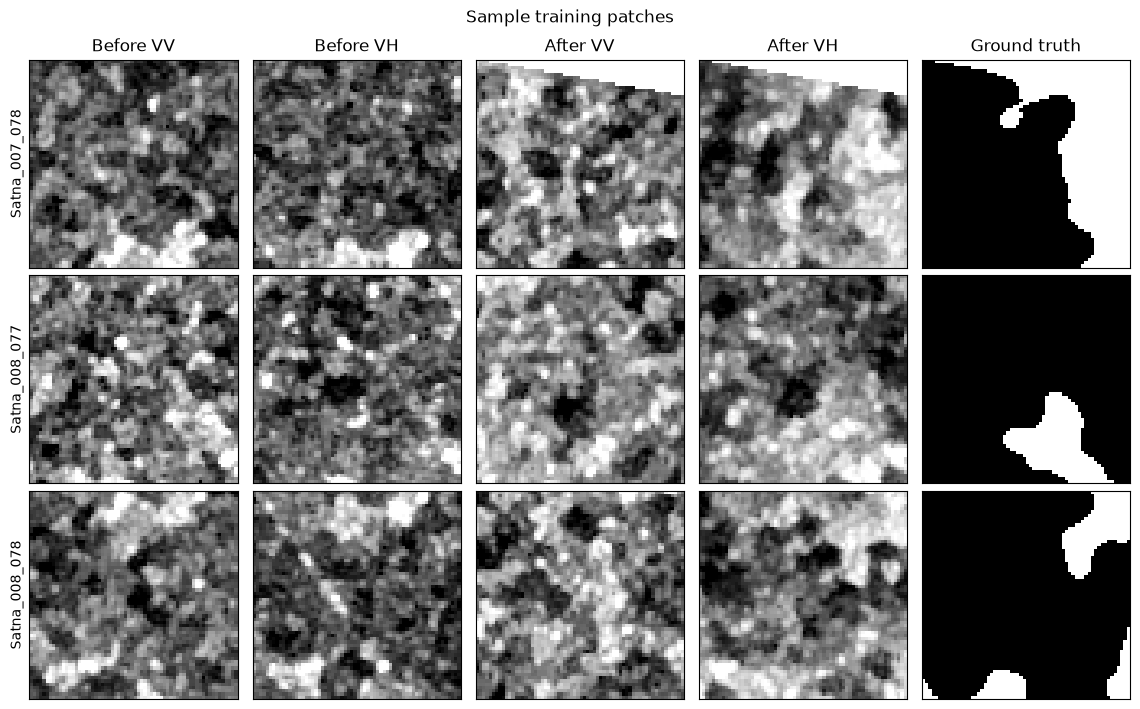

In [8]:
check_alignment(DATA_DIR, train_ids[:200] + val_ids[:200])
show_collage(train_images[:3], train_masks[:3], None, train_ids[:3], 'Sample training patches')

## 6. Training
Loss: binary cross-entropy + Dice. Optimiser: Adam (lr 1e-3), learning rate halved when the
validation loss stops improving for 5 epochs. Augmentation: random flips and 90° rotations.
The weights of the epoch with the best validation IoU are saved.

In [9]:
MODEL_CLASS = AttentionUNet
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

model = MODEL_CLASS(**MODEL_ARGS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=5)
print(f'{MODEL_CLASS.__name__}: {sum(p.numel() for p in model.parameters()):,} parameters')

history, best_iou = [], -1.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for x, y in train_loader:
        x, y = augment(x.to(device), y.to(device))
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x)

    train_loss = total_loss / len(train_loader.dataset)
    val = evaluate(model, val_loader)
    scheduler.step(val['loss'])
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val['loss'],
                        val_iou=val['iou'], val_dice=val['dice']))

    # Keep the weights of the epoch with the best validation IoU
    if val['iou'] > best_iou:
        best_iou, best_epoch = val['iou'], epoch
        torch.save({'model_state': model.state_dict(), 'model_class': MODEL_CLASS.__name__,
                    'model_args': MODEL_ARGS, 'bands': BANDS, 'mean': MEAN, 'std': STD,
                    'min_valid_frac': MIN_VALID_FRAC, 'epoch': epoch}, WEIGHTS_PATH)

    print(f'epoch {epoch:2d} | train loss {train_loss:.4f} | val loss {val["loss"]:.4f} | '
          f'val IoU {val["iou"]:.4f} | val Dice {val["dice"]:.4f}')

history = pd.DataFrame(history)
history.to_csv(f'{OUTPUT_DIR}/history.csv', index=False)
print(f'Best validation IoU {best_iou:.4f} at epoch {best_epoch}; weights saved to {WEIGHTS_PATH}')

AttentionUNet: 7,851,093 parameters


epoch  1 | train loss 0.5976 | val loss 0.4677 | val IoU 0.7306 | val Dice 0.8443


epoch  2 | train loss 0.3888 | val loss 0.3471 | val IoU 0.7700 | val Dice 0.8701


epoch  3 | train loss 0.3420 | val loss 0.3318 | val IoU 0.7853 | val Dice 0.8797


epoch  4 | train loss 0.3299 | val loss 0.3053 | val IoU 0.8004 | val Dice 0.8891


epoch  5 | train loss 0.3109 | val loss 0.3185 | val IoU 0.7833 | val Dice 0.8785


... (31 outputs left out)

epoch 37 | train loss 0.2459 | val loss 0.2340 | val IoU 0.8378 | val Dice 0.9117


epoch 38 | train loss 0.2508 | val loss 0.2421 | val IoU 0.8345 | val Dice 0.9098


epoch 39 | train loss 0.2506 | val loss 0.2867 | val IoU 0.7944 | val Dice 0.8854


epoch 40 | train loss 0.2431 | val loss 0.2325 | val IoU 0.8370 | val Dice 0.9113
Best validation IoU 0.8378 at epoch 37; weights saved to /mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project/Task III/Codes/Model_2_weights.pth


## 7. Results: IoU and Dice on the training and validation sets

In [10]:
# Reload the best weights and evaluate them on both splits (no augmentation)
model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device)['model_state'])
results = {'Training': evaluate(model, train_eval_loader), 'Validation': evaluate(model, val_loader)}

table = pd.DataFrame(results).T[['iou', 'dice', 'loss']].rename(columns={'iou': 'IoU', 'dice': 'Dice', 'loss': 'Loss'})
display(table.round(4))

summary = dict(results=results, best_epoch=best_epoch, patches=PATCH_COUNTS, band_mean=MEAN, band_std=STD,
               settings=dict(model=MODEL_CLASS.__name__, model_args=MODEL_ARGS, epochs=EPOCHS, batch_size=BATCH_SIZE,
                             lr=LR, min_valid_frac=MIN_VALID_FRAC, min_flood_frac=MIN_FLOOD_FRAC))
with open(f'{OUTPUT_DIR}/results.json', 'w') as f:
    json.dump(summary, f, indent=2)

,IoU,Dice,Loss
Training,0.8394,0.9127,0.223
Validation,0.8378,0.9117,0.234


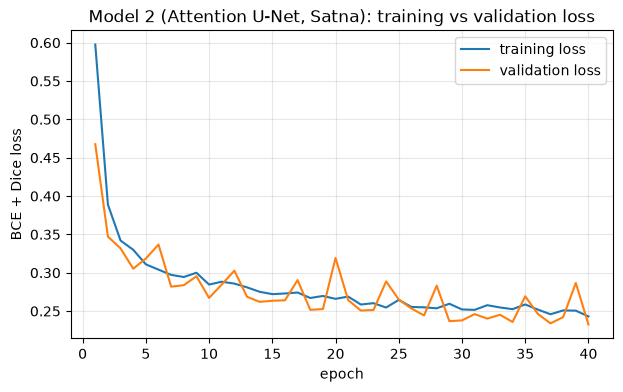

In [11]:
plot_losses(history, f'{MODEL_NAME}: training vs validation loss', f'{OUTPUT_DIR}/loss_curve.png')

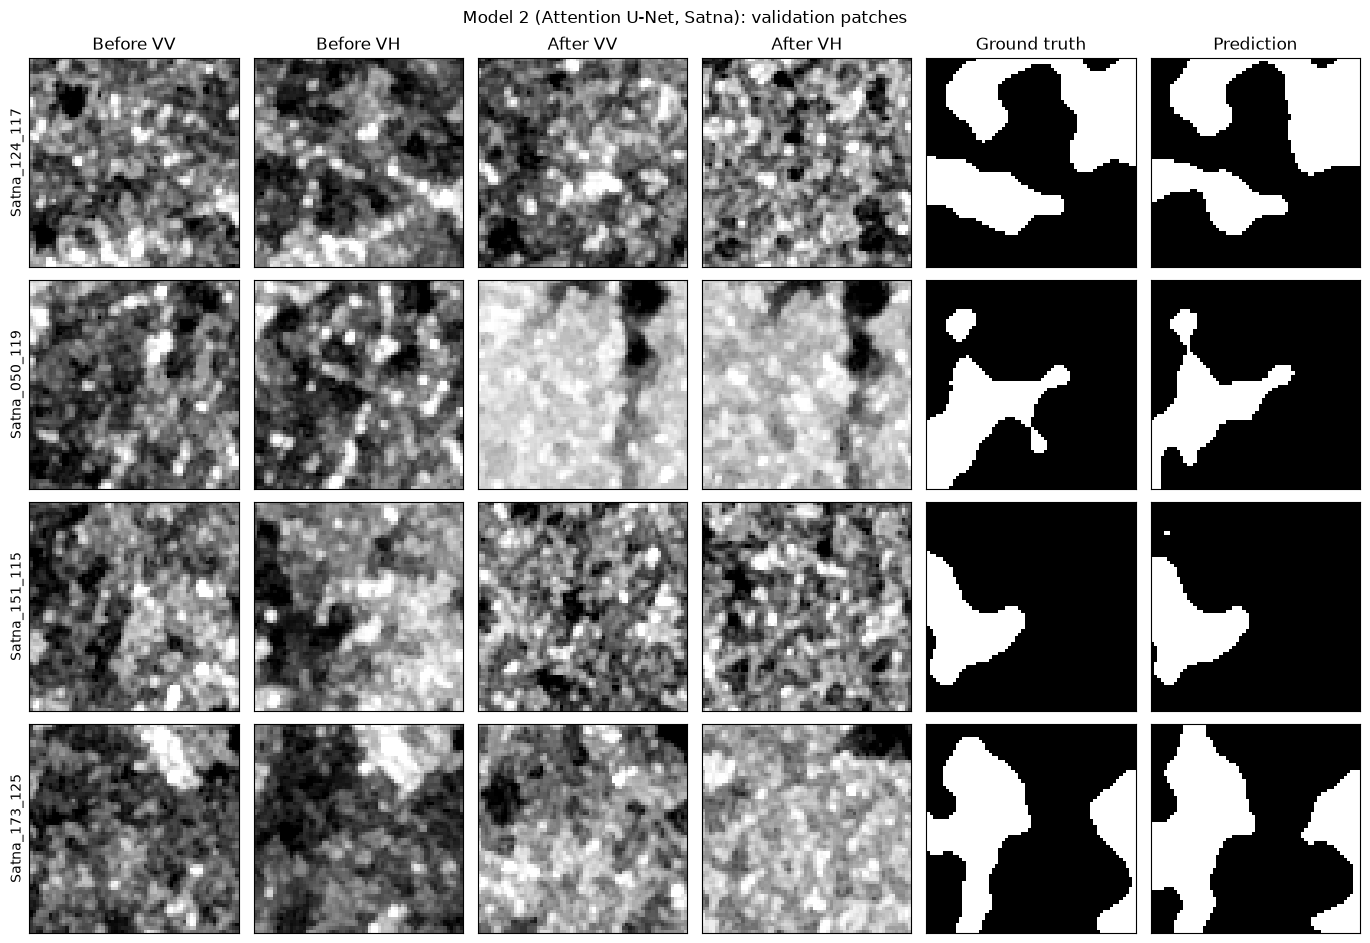

In [12]:
# Flood-mapping collage on validation patches: inputs, ground truth and prediction
rng = np.random.default_rng(SEED)
pick = rng.choice(len(val_ids), 4, replace=False)
with torch.no_grad():
    x = torch.from_numpy(normalize(val_images[pick], MEAN, STD)).to(device)
    preds = (model(x)[:, 0] > 0).float().cpu().numpy()
show_collage(val_images[pick], val_masks[pick], preds, [val_ids[i] for i in pick],
             f'{MODEL_NAME}: validation patches', f'{OUTPUT_DIR}/collage.png')

## 8. Test cell (also rebuilds the full Satna flood map)

Predicted 11669 patches, skipped 0 no-data patches.
Test IoU = 0.8308 | Test Dice = 0.9076


Saved /mnt/c/Users/Aarnav/Desktop/3-1/DL/DL Project/Task III/Outputs/Model_2/test_predictions/Satna_Before20260518_After20260910_mask.tif  (28503 x 21516 px, flood = 1.56%)


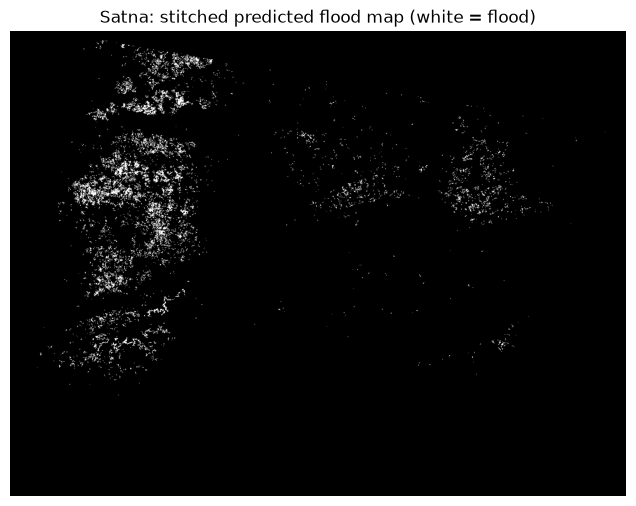

In [13]:
# =============================== TEST CELL (standalone) ===============================
# Loads the saved model, predicts a flood mask for every patch in TEST_DIR, saves every
# predicted patch as a GeoTIFF and stitches them into one flood map per region.
# This cell does not need any other cell of the notebook.
#
# TEST_DIR must use the same layout as Dataset-I:
#     TEST_DIR/before_VV/<id>_before_VV.tif   (and before_VH/, after_VV/, after_VH/)
#     TEST_DIR/mask/<id>_mask.tif              (optional - only used to report IoU / Dice)
#
# Google Colab: mount Google Drive (cell 1), then run this cell.
# Local computer:
#     1. pip install torch numpy rasterio matplotlib
#     2. change TEST_DIR, WEIGHTS_PATH and OUTPUT_DIR below to local paths,
#        e.g. TEST_DIR = r"D:\Flood_Data\Dataset_II"
#     3. run the cell in Jupyter, or paste it into test.py and run `python test.py` (GPU optional).
# ======================================================================================
import os, sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio'], check=True)   # only package Colab lacks
    PROJECT_DIR = '/content/drive/MyDrive/DL_Project'
else:
    PROJECT_DIR = os.path.abspath('../..')       # this notebook lives in <PROJECT_DIR>/Task III/Codes
DISTRICT = 'Satna'
TEST_DIR = f'{PROJECT_DIR}/Task III/Dataset_II'                         # any folder in Dataset-I layout
WEIGHTS_PATH = f'{PROJECT_DIR}/Task III/Codes/Model_2_weights.pth'
OUTPUT_DIR = f'{PROJECT_DIR}/Task III/Outputs/Model_2/test_predictions'
REFERENCE_TIF = f'{PROJECT_DIR}/{DISTRICT}/Mask/Cleaned_flood_mask.tif'  # optional full-district grid (skipped if missing)
DATES = {DISTRICT: ('20260518', '20260910')}                            # region -> (before, after) date

import os, glob
import numpy as np
import rasterio
from rasterio.transform import from_origin

BANDS = ['before_VV', 'before_VH', 'after_VV', 'after_VH']   # channel order of the model input
PATCH = 64                                                    # patch size in pixels


def read_tif(path):
    """Return (band 1 as array, geo-transform, CRS) of a GeoTIFF."""
    with rasterio.open(path) as src:
        return src.read(1), src.transform, src.crs


def write_tif(path, array, transform, crs):
    """Save a single-band uint8 GeoTIFF (0 = no flood, 255 = flood)."""
    profile = dict(driver='GTiff', height=array.shape[0], width=array.shape[1], count=1,
                   dtype='uint8', crs=crs, transform=transform, compress='lzw')
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(array, 1)


def patch_ids(folder):
    """IDs of all patches in a Dataset-I style folder, e.g. 'K_012_034' = region_row_col."""
    files = glob.glob(f'{folder}/after_VH/*_after_VH.tif')
    return sorted(os.path.basename(f)[:-len('_after_VH.tif')] for f in files)


def read_patch(folder, pid):
    """Return the 4 stacked SAR bands (4, 64, 64) in dB, the 0/1 mask (None if missing),
    and the geo-transform + CRS of the patch."""
    bands = [read_tif(f'{folder}/{band}/{pid}_{band}.tif') for band in BANDS]
    image = np.stack([array for array, _, _ in bands]).astype(np.float32)
    _, transform, crs = bands[0]

    mask_path = f'{folder}/mask/{pid}_mask.tif'
    mask = (read_tif(mask_path)[0] > 0).astype(np.float32) if os.path.exists(mask_path) else None
    return image, mask, transform, crs


def valid_pixels(image):
    """No-data pixels are NaN or exactly 0 dB (outside the satellite swath)."""
    return np.isfinite(image) & (image != 0)


def normalize(image, mean, std):
    """Standardise each band with the training mean/std. No-data pixels become 0 (= the band mean)."""
    mean = np.asarray(mean, np.float32)[:, None, None]
    std = np.asarray(std, np.float32)[:, None, None]
    return np.where(valid_pixels(image), (image - mean) / std, 0).astype(np.float32)

import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Sequential):
    """Two (3x3 convolution -> batch norm -> ReLU) layers."""
    def __init__(self, in_ch, out_ch):
        super().__init__(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018): scales every skip-connection pixel by a
    0..1 weight computed from the skip features and the decoder (gating) features."""
    def __init__(self, channels):
        super().__init__()
        self.w_skip = nn.Conv2d(channels, channels // 2, 1)
        self.w_gate = nn.Conv2d(channels, channels // 2, 1)
        self.psi = nn.Sequential(nn.ReLU(inplace=True), nn.Conv2d(channels // 2, 1, 1), nn.Sigmoid())

    def forward(self, skip, gate):
        weights = self.psi(self.w_skip(skip) + self.w_gate(gate))    # (B, 1, H, W)
        return skip * weights


class AttentionUNet(nn.Module):
    """U-Net whose skip connections pass through attention gates, so the decoder can focus
    on flood-relevant regions and ignore background clutter (speckle, vegetation change)."""
    def __init__(self, in_channels=4, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]          # 32, 64, 128, 256, 512
        self.encoders = nn.ModuleList([DoubleConv(in_channels, ch[0])] +
                                      [DoubleConv(ch[i], ch[i + 1]) for i in range(4)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(4)])
        self.gates = nn.ModuleList([AttentionGate(ch[i]) for i in range(4)])
        self.decoders = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in range(4)])
        self.head = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x):
        skips = []
        for i, encoder in enumerate(self.encoders):
            x = encoder(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()                                               # bottleneck (4x4)
        for i in reversed(range(4)):
            up = self.ups[i](x)
            skip = self.gates[i](skips[i], up)                       # attention-weighted skip
            x = self.decoders[i](torch.cat([up, skip], dim=1))
        return self.head(x)

import matplotlib.pyplot as plt
MODEL_CLASS = AttentionUNet
def stitch(patches, reference_tif=None):
    """Put predicted patches back at their map position using their geo-transforms.
    Places without a patch (skipped no-data / low-flood patches) stay 0 = background.
    Overlapping patches are merged with a pixel-wise maximum (flood if any patch says flood).
    Without a reference raster the output grid is the smallest one covering all patches."""
    _, first_transform, crs = patches[0]
    pixel = first_transform.a
    if reference_tif and os.path.exists(reference_tif):   # fall back to the patch extent if missing
        with rasterio.open(reference_tif) as ref:
            transform, height, width = ref.transform, ref.height, ref.width
    else:
        left = min(t.c for _, t, _ in patches)
        top = max(t.f for _, t, _ in patches)
        transform = from_origin(left, top, pixel, pixel)
        width = round((max(t.c for _, t, _ in patches) - left) / pixel) + PATCH
        height = round((top - min(t.f for _, t, _ in patches)) / pixel) + PATCH

    full_map = np.zeros((height, width), np.uint8)
    for pred_mask, t, _ in patches:
        col = round((t.c - transform.c) / pixel)
        row = round((transform.f - t.f) / pixel)
        window = full_map[row:row + PATCH, col:col + PATCH]
        np.maximum(window, pred_mask, out=window)
    return full_map, transform, crs


# ---- load the saved model ----
device = 'cuda' if torch.cuda.is_available() else 'cpu'
checkpoint = torch.load(WEIGHTS_PATH, map_location=device)
model = MODEL_CLASS(**checkpoint['model_args']).to(device).eval()
model.load_state_dict(checkpoint['model_state'])
mean, std, min_valid = checkpoint['mean'], checkpoint['std'], checkpoint['min_valid_frac']

# ---- predict every patch ----
os.makedirs(f'{OUTPUT_DIR}/pred_mask', exist_ok=True)
predictions = {}                      # patch id -> (predicted 0/255 mask, transform, crs)
tp = fp = fn = skipped = 0
for pid in patch_ids(TEST_DIR):
    image, mask, transform, crs = read_patch(TEST_DIR, pid)
    valid = valid_pixels(image)
    if valid.mean(axis=(1, 2)).min() < min_valid:           # black / no-data patch -> background
        skipped += 1
        continue

    x = torch.from_numpy(normalize(image, mean, std))[None].to(device)
    with torch.no_grad():
        pred = (model(x)[0, 0] > 0).cpu().numpy()            # logit > 0  <=>  probability > 0.5
    pred &= valid.all(axis=0)                                # no-data pixels are never flood
    pred_mask = pred.astype(np.uint8) * 255
    write_tif(f'{OUTPUT_DIR}/pred_mask/{pid}_pred_mask.tif', pred_mask, transform, crs)
    predictions[pid] = (pred_mask, transform, crs)

    if mask is not None:
        truth = mask > 0
        tp += np.sum(pred & truth)
        fp += np.sum(pred & ~truth)
        fn += np.sum(~pred & truth)

print(f'Predicted {len(predictions)} patches, skipped {skipped} no-data patches.')
if tp + fp + fn > 0:
    print(f'Test IoU = {tp / (tp + fp + fn):.4f} | Test Dice = {2 * tp / (2 * tp + fp + fn):.4f}')

# ---- stitch the patches into one flood map per region ----
regions = sorted({pid.rsplit('_', 2)[0] for pid in predictions})       # 'K_012_034' -> 'K'
for region in regions:
    patches = [value for pid, value in predictions.items() if pid.rsplit('_', 2)[0] == region]
    full_map, transform, crs = stitch(patches, REFERENCE_TIF)
    before, after = DATES.get(region, ('YYYYMMDD', 'YYYYMMDD'))
    path = f'{OUTPUT_DIR}/{region}_Before{before}_After{after}_mask.tif'
    write_tif(path, full_map, transform, crs)
    print(f'Saved {path}  ({full_map.shape[1]} x {full_map.shape[0]} px, flood = {(full_map > 0).mean():.2%})')

    step = max(1, max(full_map.shape) // 1500)                         # downsample for display only
    plt.figure(figsize=(8, 8 * full_map.shape[0] / full_map.shape[1]))
    plt.imshow(full_map[::step, ::step], cmap='gray')
    plt.title(f'{region}: stitched predicted flood map (white = flood)')
    plt.axis('off')
    plt.show()